# 10.3.3 Poço offshore

Rede com 7 arestas: poço (aresta 1, líquido, 300 m; aresta 2, mistura, 1500 m),
linha de produção (aresta 3: 3500 m horizontal + trecho descendente de 1000 m
com −100 m), riser (aresta 4, 1500 m), linha de entrega de gás (5), linha de
gás até a válvula choke de gás (6) e anular de gás (7). Reservatório a 225 bar,
chokes de produção (Cv = 30) e de gás (Cv = 5), conexões entre arestas.
Modelo a 3 equações (intermitente) nas arestas bifásicas e monofásicos nas
demais; diferenças finitas centrais.

Cenário: choke de gás 100 % → 80 % entre 100 e 200 s. Figuras 10.48 a 10.54.

In [1]:
import numpy as np, matplotlib.pyplot as plt
from mfsim.notebook_utils import describe, run_case, compare_states, show_pipe, plot_elements, plot_vertices

describe("10.3.3")
case, raw, res = run_case("10.3.3")
compare_states(res, raw)

10.3.3 Poço offshore
Poço + linha de produção (3500 m horizontal + trecho descendente) + riser de 1500 m, gas lift com linha de gás e anular; choke de gás 100%->80% entre 100 e 200 s.
Figuras da tese: Figs. 10.48-10.54


[implicit BDF] steps=78 rejected=9 rhs=678 jac=13 | 1.0s
tempo de CPU: 1.03 s
duto modelo       var      máx |dif|   faixa MATLAB  dif/faixa
   1 liquid       PT        5.74e-05       2.34e-01   2.45e-04
   1 liquid       qL        1.71e-03       2.13e-01   8.04e-03
   2 beggs_brill  PT        6.63e-05       7.56e-01   8.76e-05
   2 beggs_brill  qL        5.03e-03       2.09e-01   2.40e-02
   2 beggs_brill  qG        6.83e-04       2.33e-02   2.93e-02
   3 beggs_brill  PT        8.23e-05       9.50e-02   8.66e-04
   3 beggs_brill  qL        8.92e-03       2.74e-01   3.26e-02
   3 beggs_brill  qG        7.59e-04       4.25e-02   1.78e-02
   4 beggs_brill  PT        1.26e-04       6.03e-01   2.09e-04
   4 beggs_brill  qL        1.13e-02       6.52e-01   1.74e-02
   4 beggs_brill  qG        1.23e-03       6.41e-02   1.91e-02
   5 gas          PT        5.08e-07       1.77e-03   2.87e-04
   5 gas          qG        1.22e-04       1.46e-02   8.33e-03
   6 gas          PT        3.27e-05    

## Figuras 10.48-10.54

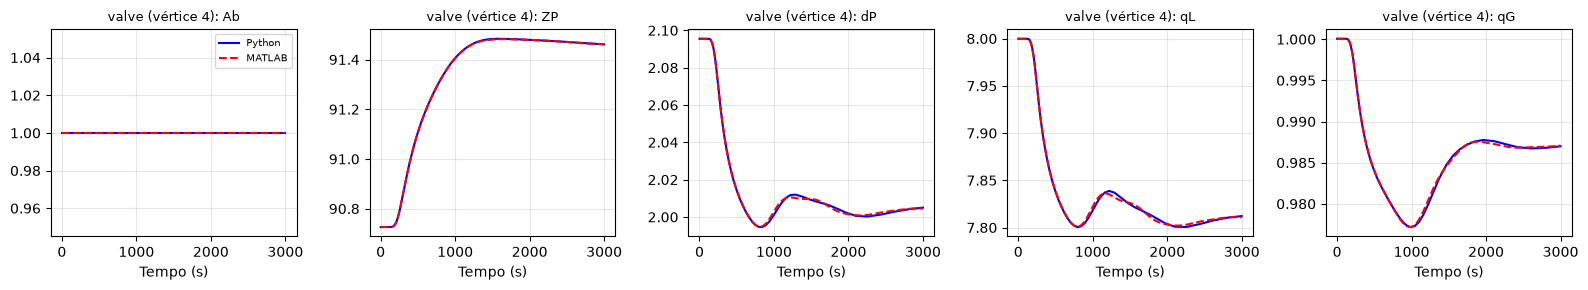

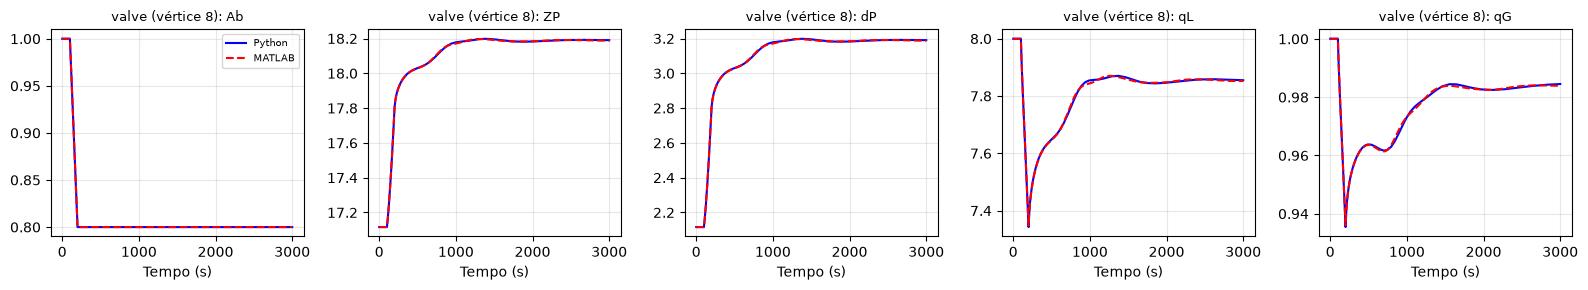

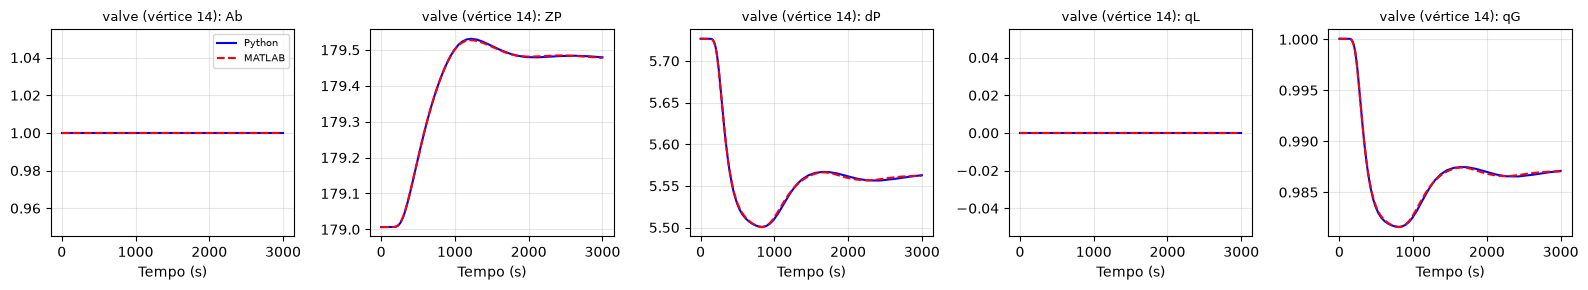

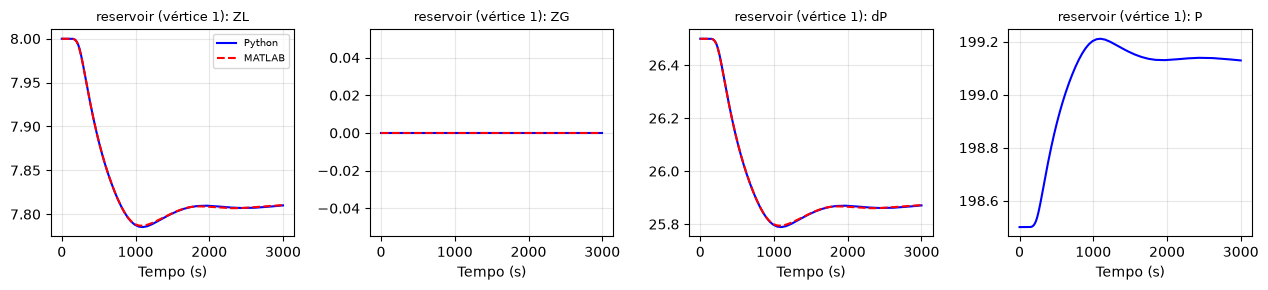

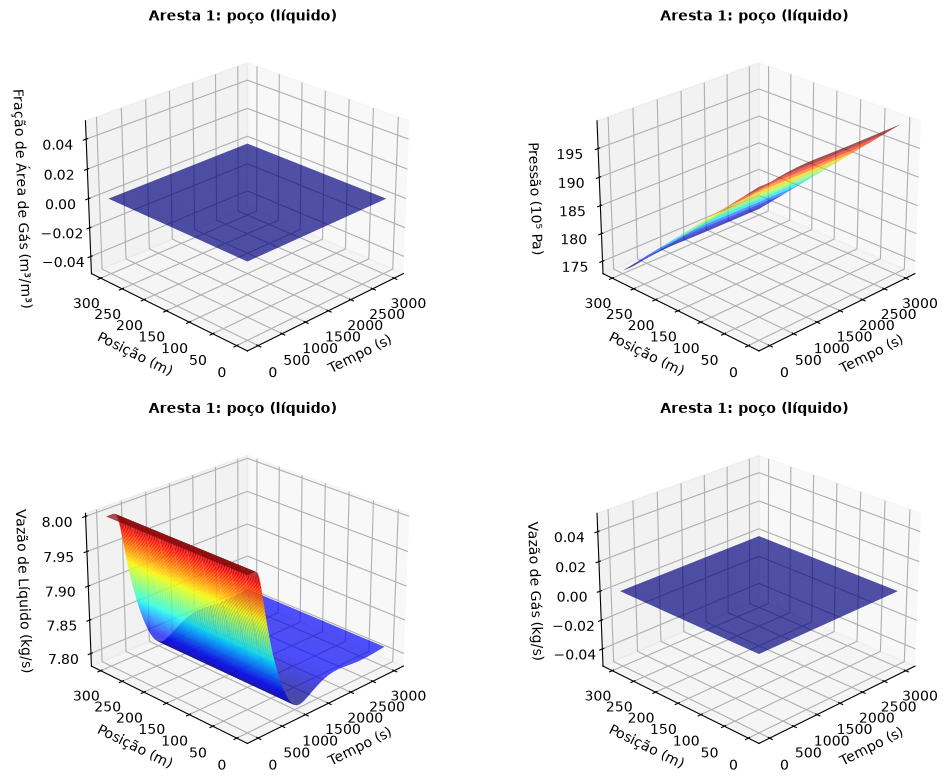

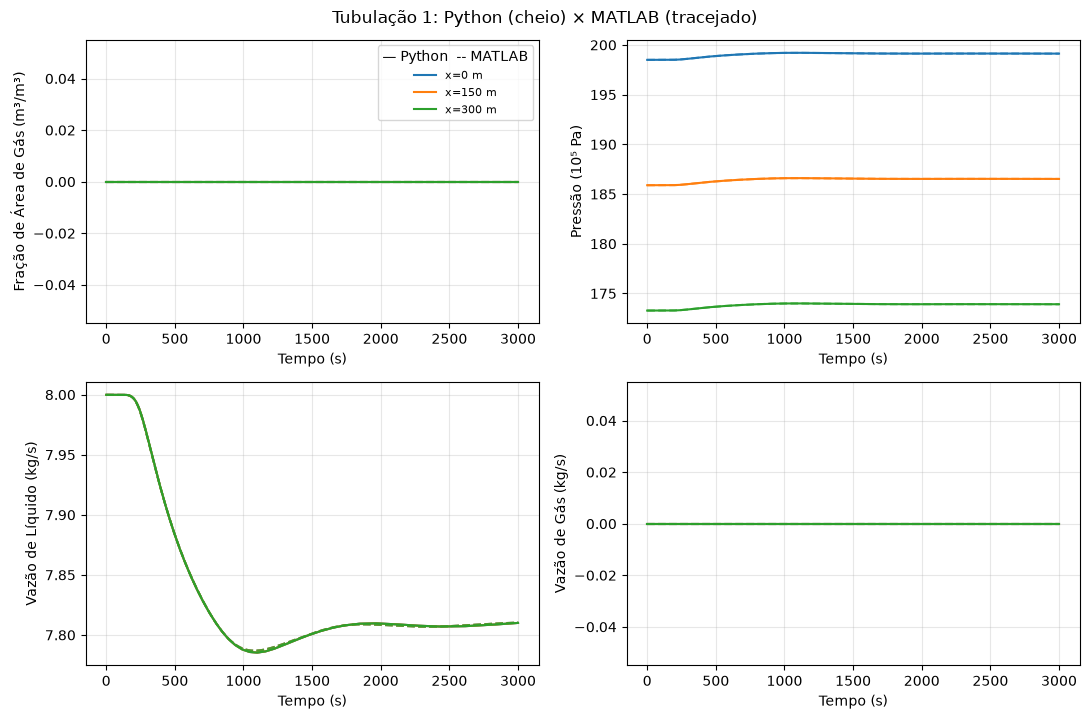

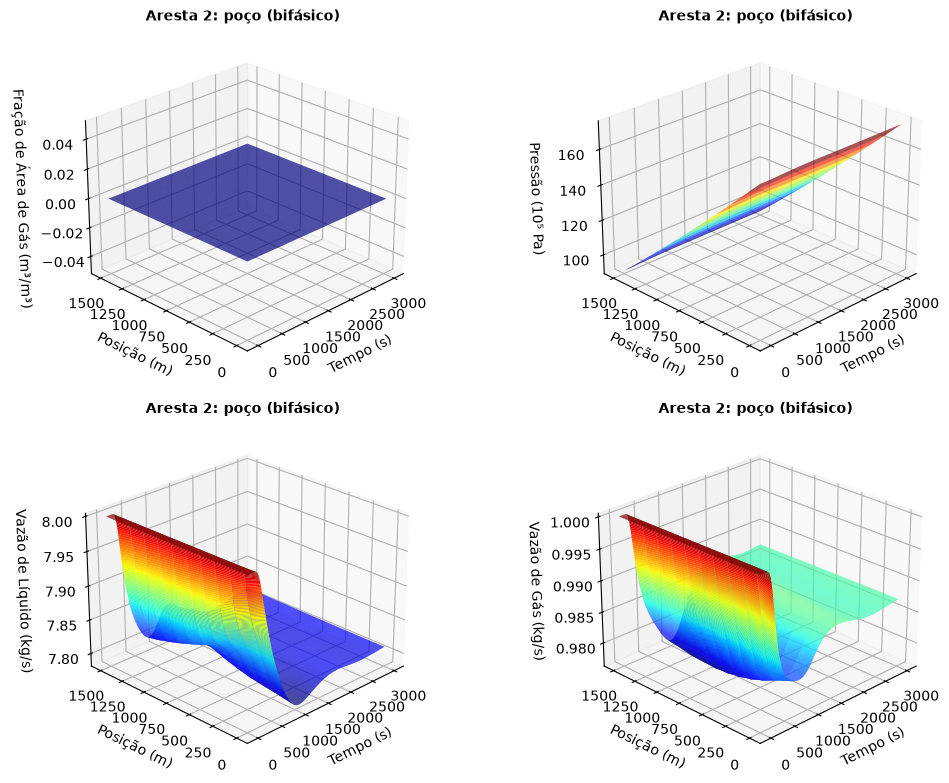

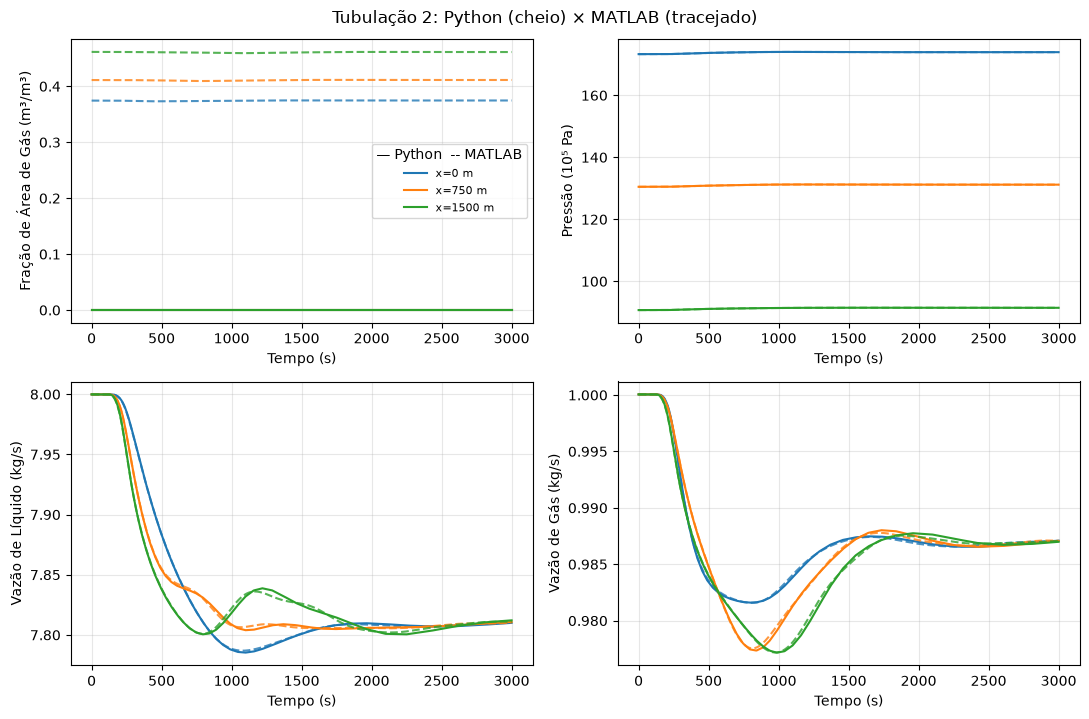

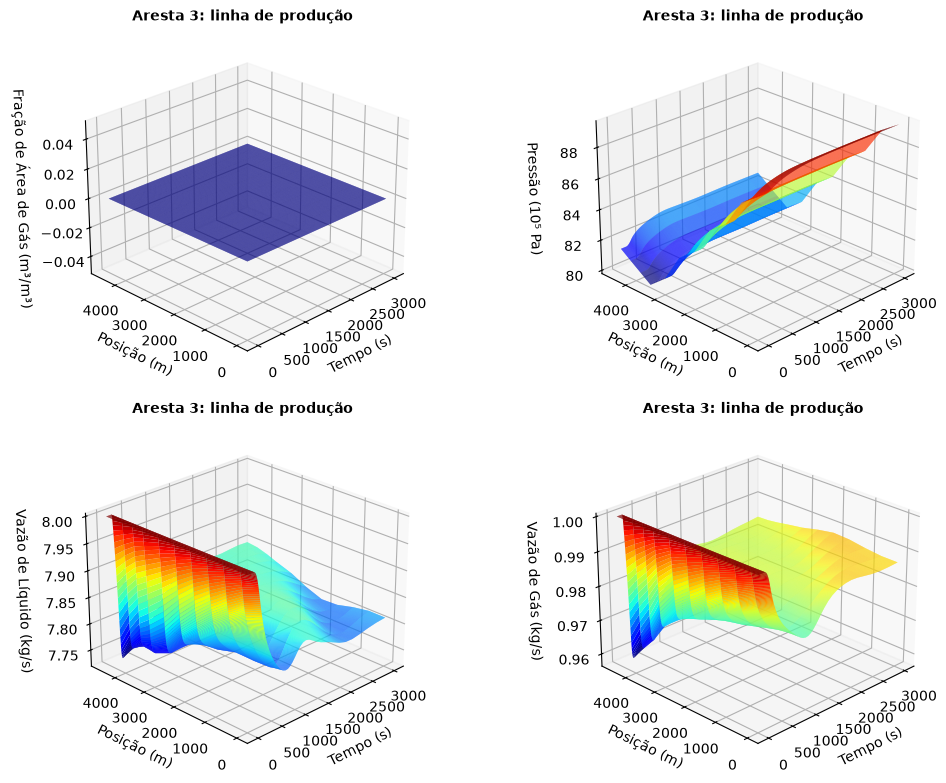

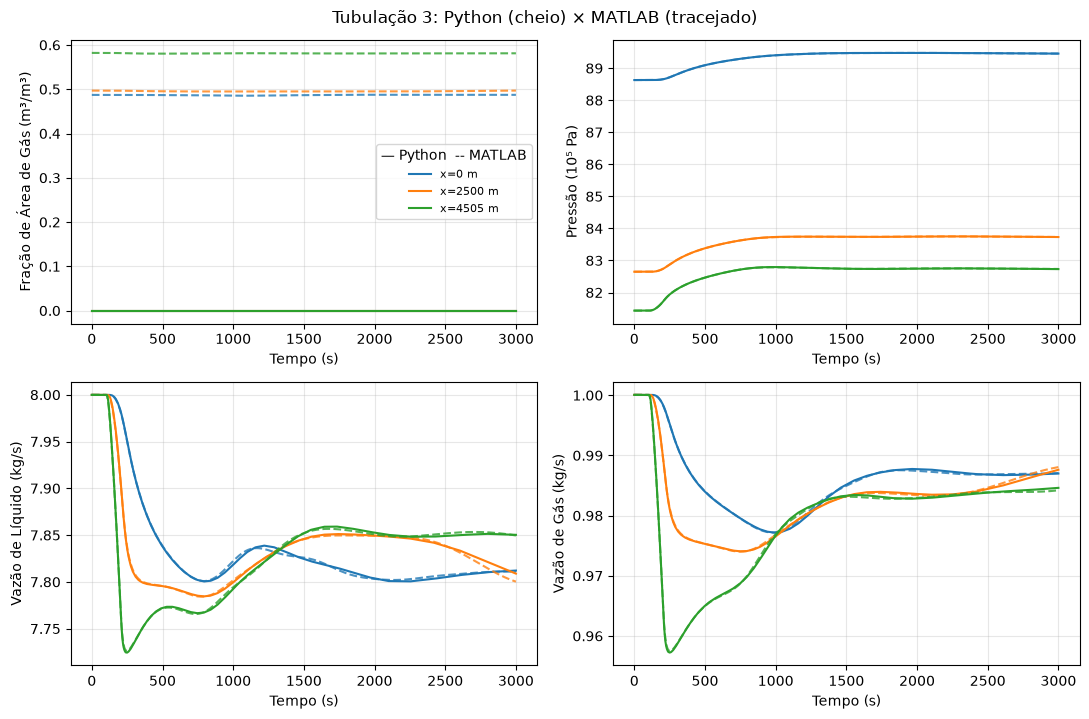

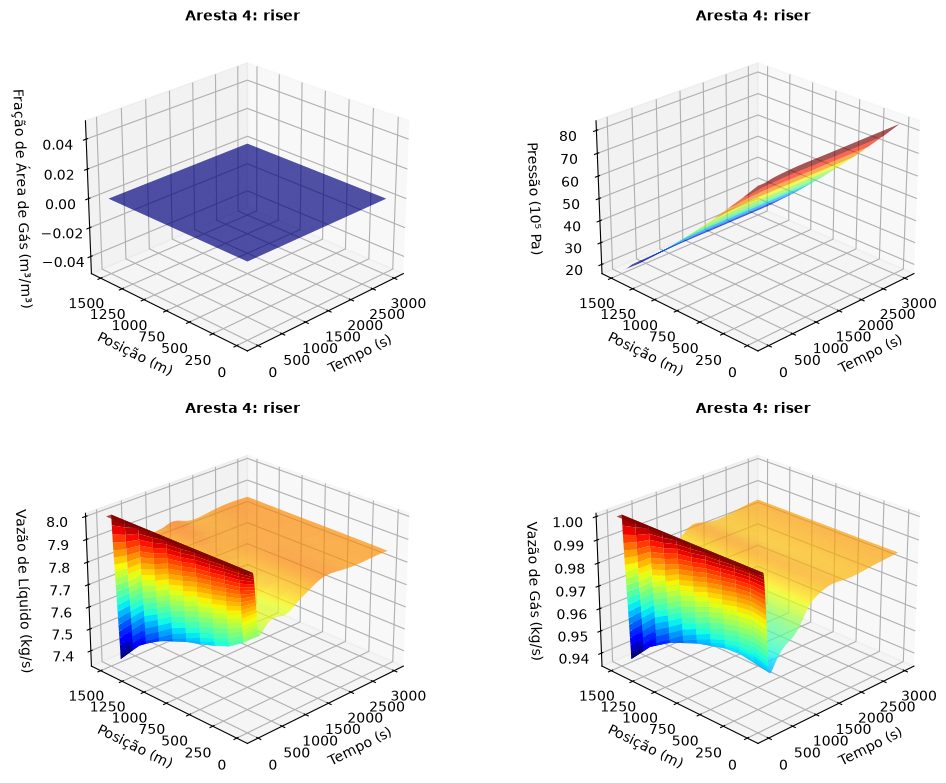

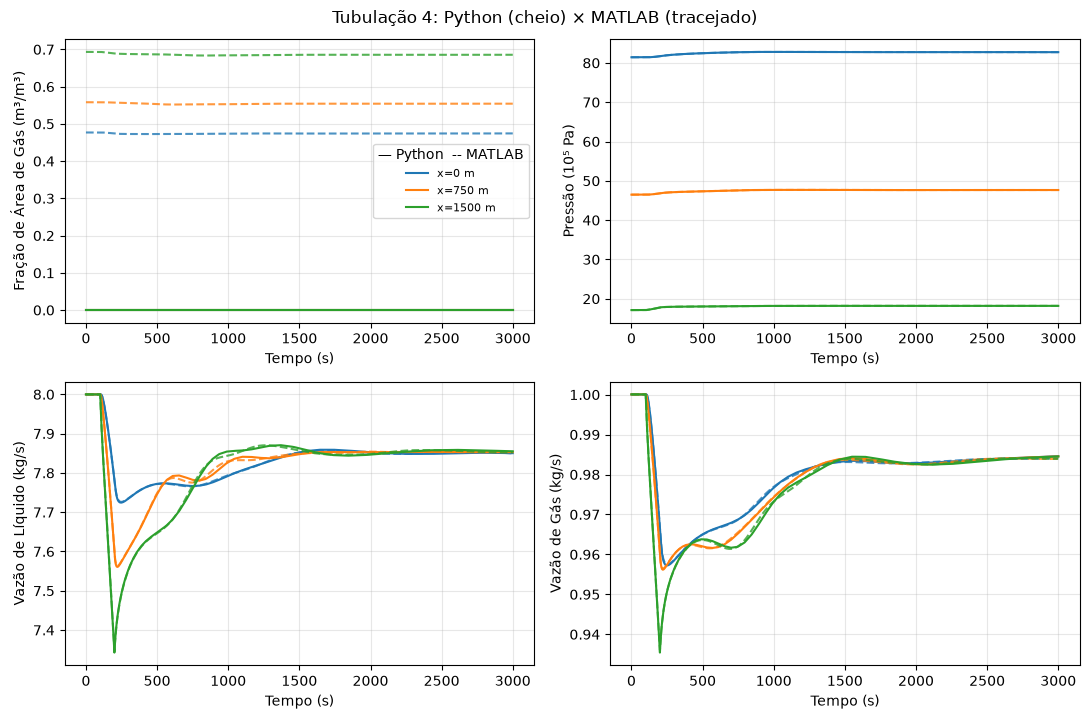

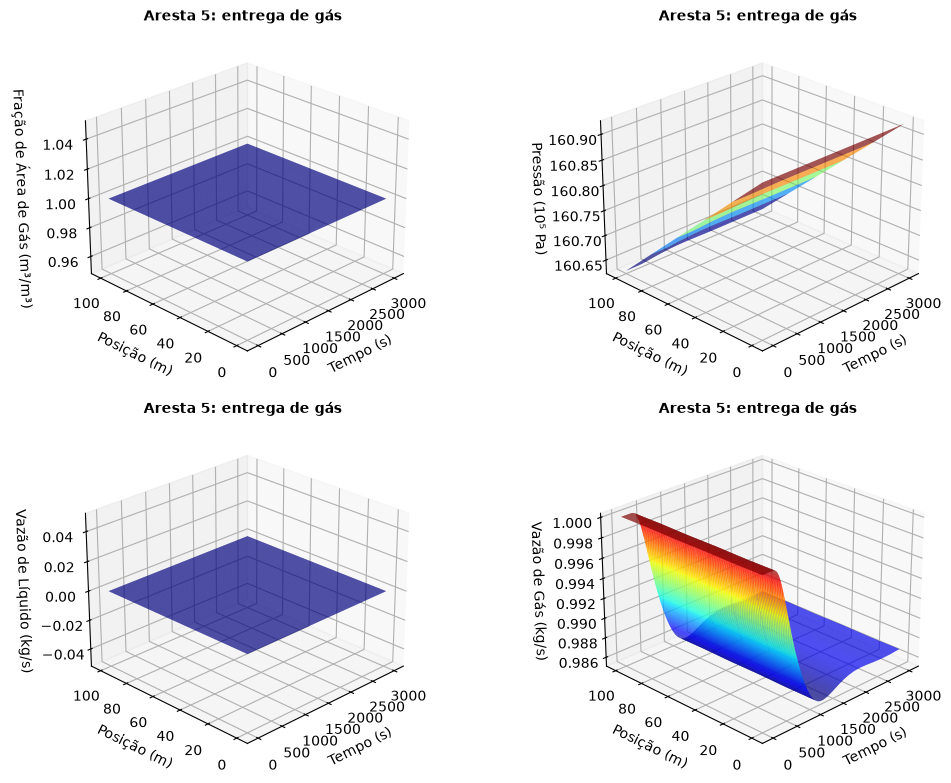

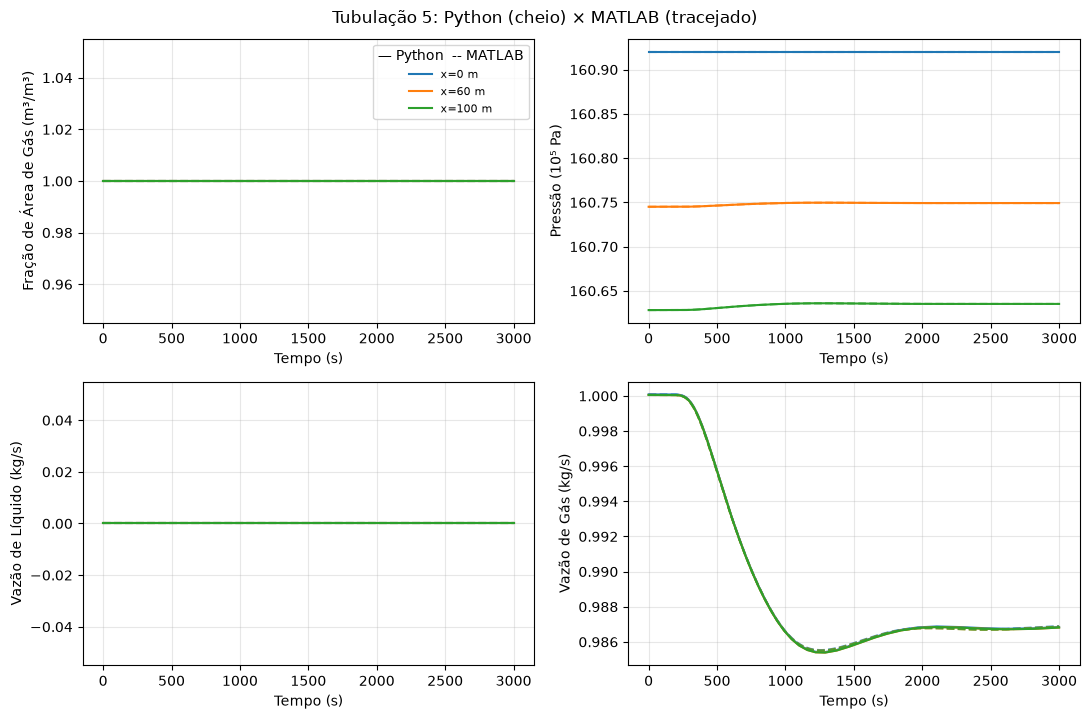

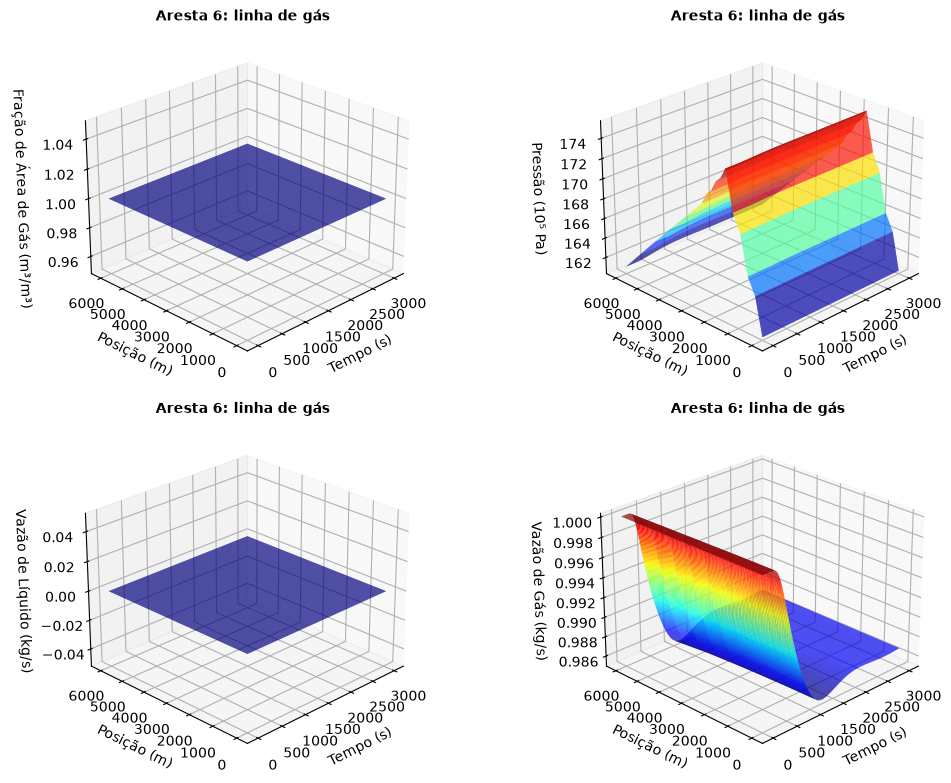

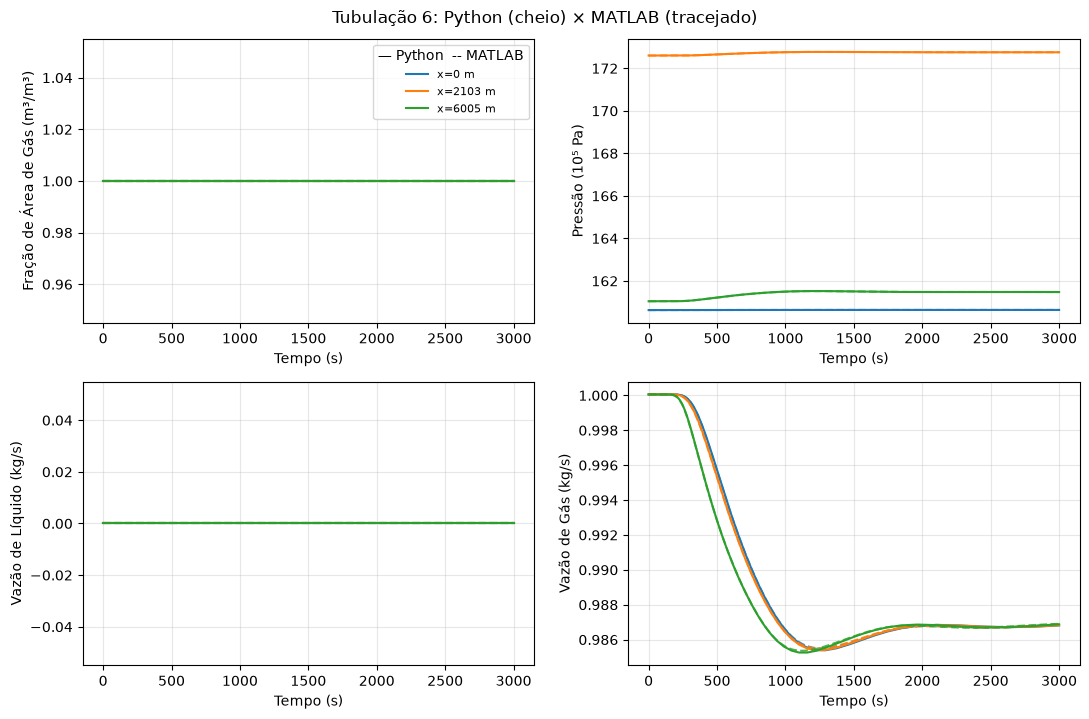

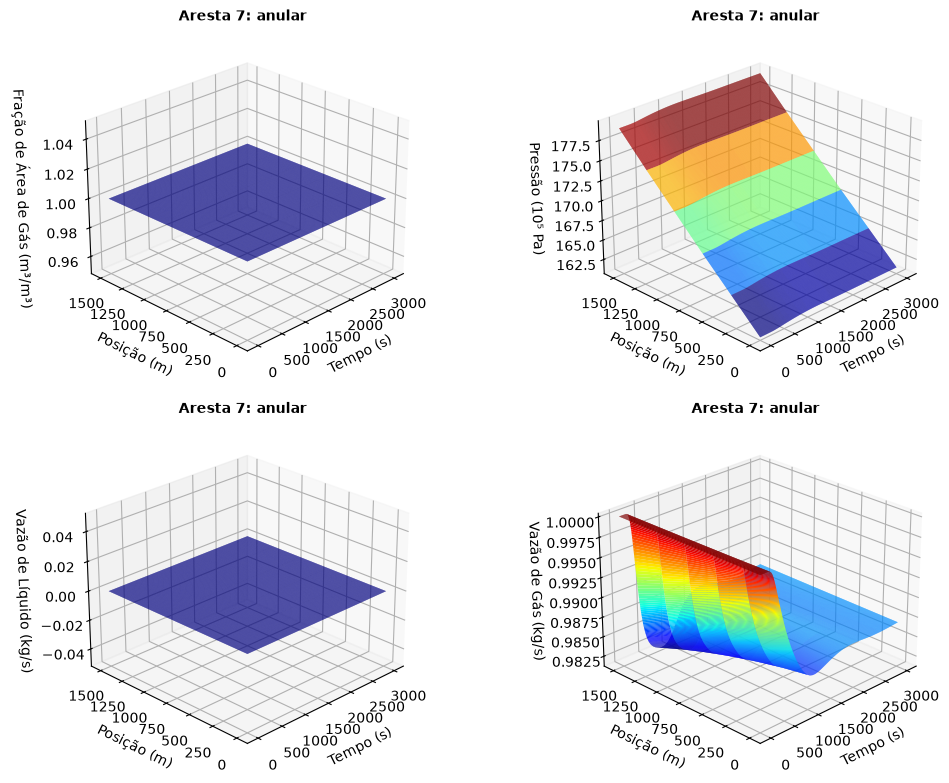

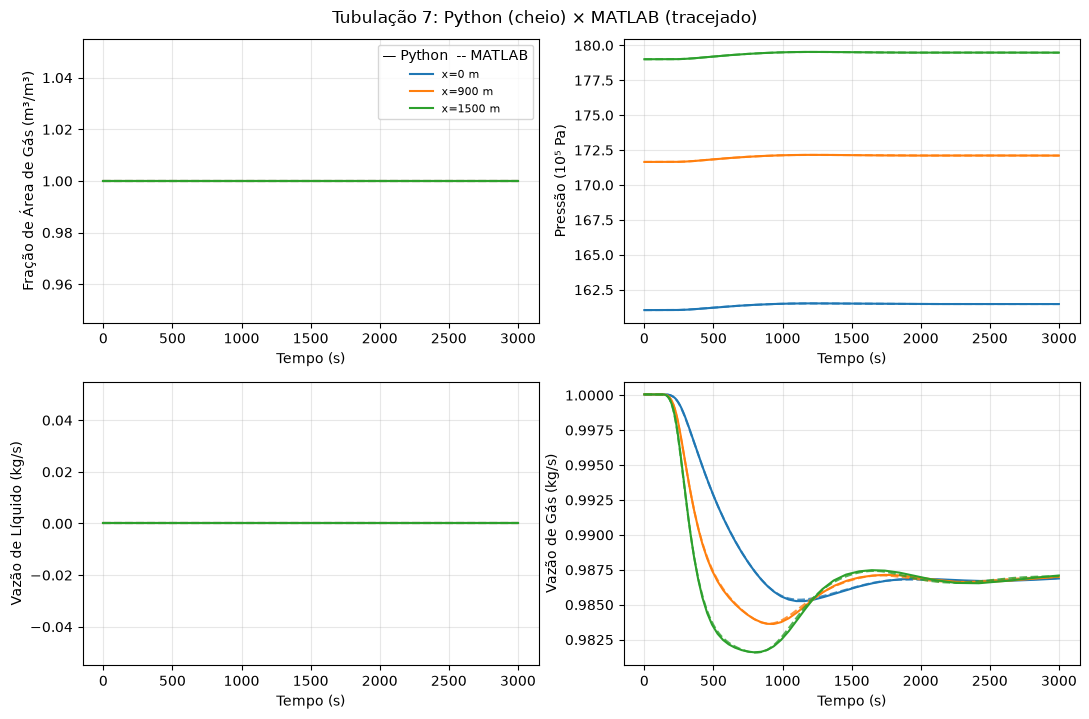

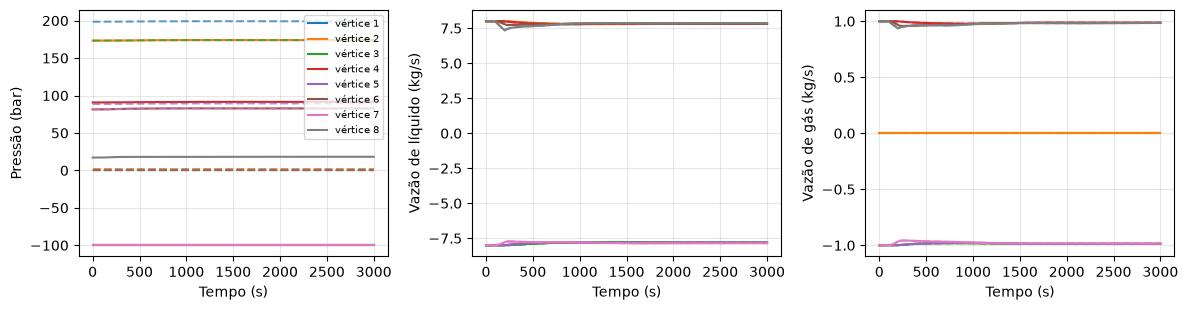

In [2]:
plot_elements(res, raw)
names = ["poço (líquido)", "poço (bifásico)", "linha de produção", "riser", "entrega de gás", "linha de gás", "anular"]
for k, nm in enumerate(names):
    show_pipe(res, raw, k, title=f"Aresta {k + 1}: {nm}")
plot_vertices(res, raw, indices=[1, 2, 3, 4, 5, 6, 7, 8])

## Lado direito compilado (JAX)
A mesma simulação com `simulate(..., jax=True)`: lado direito compilado por
`jax.jit` e Jacobiana exata por diferenciação automática (`mfsim/compiled.py`, o mesmo código numpy com o backend JAX),
no lugar das diferenças finitas coloridas. O resultado deve coincidir com a versão
numpy dentro da tolerância do integrador (as sequências de passos podem diferir
porque a Jacobiana muda o Newton); o ganho de tempo cresce com o número de passos
e de Jacobianas.

In [3]:
from mfsim.notebook_utils import jax_comparison
res_jax = jax_comparison(case, res, rtol=1e-4, atol=1e-6)

JAX: 1.40 s (78 passos; compilação 1.62 s, uma vez por modelo) | numpy: 1.03 s (78 passos) | diferença máxima relativa dos estados 2.1e-05
